# Phase 4 — benchmark eligibility and robustness
Decision: **inconclusive**. Independent quantitative T-cell-function outcomes are unavailable. Patient resampling measures descriptive rank stability, not functional prediction accuracy.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
m=json.loads((ROOT/'results/phase4_manifest.json').read_text())
display(m['decision'])
display(pd.read_csv(ROOT/'results/evaluation_metrics.csv'))

{'quantitative_families': 1,
 'eligible_independent_records': 0,
 'decision': 'inconclusive',
 'source_partition_check': 'passed',
 'endpoint_check': 'passed',
 'note': 'No eligible unseen direct functional outcomes; no independent metrics computed.'}

,model,endpoint,metric,estimate,ci_lower,ci_upper,test_studies,test_genes,status,reason
0,transcriptomic_association,direct_T_cell_function,AUPRC,NaN,NaN,NaN,0,0,not_estimable,no_compatible_independent_quantitative_T_cell_...
1,transcriptomic_association,direct_T_cell_function,precision_at_20,NaN,NaN,NaN,0,0,not_estimable,no_compatible_independent_quantitative_T_cell_...
2,transcriptomic_association,direct_T_cell_function,spearman_functional_effect,NaN,NaN,NaN,0,0,not_estimable,no_compatible_independent_quantitative_T_cell_...
3,absolute_effect,direct_T_cell_function,AUPRC,NaN,NaN,NaN,0,0,not_estimable,no_compatible_independent_quantitative_T_cell_...
4,absolute_effect,direct_T_cell_function,precision_at_20,NaN,NaN,NaN,0,0,not_estimable,no_compatible_independent_quantitative_T_cell_...
5,absolute_effect,direct_T_cell_function,spearman_functional_effect,NaN,NaN,NaN,0,0,not_estimable,no_compatible_independent_quantitative_T_cell_...
6,composition_adjusted,direct_T_cell_function,AUPRC,NaN,NaN,NaN,0,0,not_estimable,no_compatible_independent_quantitative_T_cell_...
7,composition_adjusted,direct_T_cell_function,precision_at_20,NaN,NaN,NaN,0,0,not_estimable,no_compatible_independent_quantitative_T_cell_...
8,composition_adjusted,direct_T_cell_function,spearman_functional_effect,NaN,NaN,NaN,0,0,not_estimable,no_compatible_independent_quantitative_T_cell_...
9,integrated_marker_proxy,direct_T_cell_function,AUPRC,NaN,NaN,NaN,0,0,not_estimable,no_compatible_independent_quantitative_T_cell_...


In [2]:
display(pd.read_csv(ROOT/'results/phase4_family_audit.csv'))
display(pd.read_csv(ROOT/'results/phase4_leave_patient_out.csv'))

,split_group,partition,endpoint_class,rows,mapped,numeric
0,kiritsy_olive_2021,development,T_cell_function_qualitative,4,4,0
1,kiritsy_olive_2021,development,immune_marker_proxy,35103,31536,35103
2,marelli_2025,excluded_not_pristine_test,T_cell_function_qualitative,2,0,0


,endpoint,omitted_patient,common_genes,variant_available,rank_spearman,top20_overlap,max_rank_change,status
0,CD40,P0006,5155,5155,0.920520,14,3740.0,descriptive_only
1,CD40,P0008,5155,5155,0.927740,13,2733.0,descriptive_only
2,CD40,P0009,5155,5155,0.924777,15,3128.0,descriptive_only
3,CD40,P0018,5155,5155,0.938965,17,3197.0,descriptive_only
4,CD40,P0019,5155,5155,0.792070,10,3613.0,descriptive_only
5,CD40,P0020,5155,5155,0.885764,11,3571.0,descriptive_only
6,CD40,P0025,5155,5155,0.950007,14,3025.0,descriptive_only
7,CD40,P0028,5155,5155,0.773325,13,3682.0,descriptive_only
8,CD40,P0030,5155,5155,0.917622,15,3291.0,descriptive_only
9,CD40,P0031,5155,5155,0.979571,13,2623.0,descriptive_only


In [3]:
display(pd.read_csv(ROOT/'results/phase4_ablation_metrics.csv'))

,endpoint,comparison,common_genes,variant_available,rank_spearman,top20_overlap,max_rank_change,status,interpretation
0,CD40,transcriptomic_only,5155,5155,0.687174,2.0,2574.0,descriptive_only,descriptive_rank_agreement
1,CD40,marker_only,5155,5155,0.686510,1.0,2575.0,descriptive_only,descriptive_rank_agreement
2,CD40,composition_adjusted,5155,5155,0.626683,8.0,3756.0,descriptive_only,descriptive_rank_agreement
3,CD40,within_state,5155,5155,0.678699,4.0,3729.0,descriptive_only,descriptive_rank_agreement
4,CD40,exclude_indirect,0,0,NaN,NaN,NaN,not_estimable,no_eligible_evidence
5,CD40,leave_development_family_out,0,0,NaN,NaN,NaN,not_estimable,no_eligible_evidence
6,CD40,CD8,5155,5155,0.549344,1.0,3784.0,descriptive_only,different_T_endpoint
7,CD40,adaptive_qc,5155,5155,0.898930,10.0,3249.0,descriptive_only,descriptive_rank_agreement
8,CD40,age,5155,5155,0.731447,6.0,3703.0,descriptive_only,descriptive_rank_agreement
9,CD40,cytotoxic,5155,5155,0.608086,3.0,3739.0,descriptive_only,different_T_endpoint


In [4]:
draws=pd.read_csv(ROOT/'results/phase4_bootstrap_draws.csv')
display(draws[['unique_patients','estimable_genes']].describe())
r=pd.read_csv(ROOT/'results/phase4_rank_resampling.csv')
for endpoint,g in r.groupby('endpoint'):
    print(endpoint)
    display(g.sort_values(['reference_rank','gene_symbol']).head(10))

,unique_patients,estimable_genes
count,300.000000,300.0
mean,7.190000,6124.0
std,1.057178,0.0
min,5.000000,6124.0
25%,7.000000,6124.0
50%,7.000000,6124.0
75%,8.000000,6124.0
max,10.000000,6124.0


CD40


,endpoint,gene_symbol,reference_rank,rank_q025,rank_median,rank_q975,valid_draws,top20_count,top20_frequency_all_draws,top20_frequency_valid_draws,loo_min_rank,loo_max_rank,max_loo_rank_change
4198,CD40,SPTY2D1,1,1.000,36.5,1674.825,300,119,0.396667,0.396667,1.0,13.0,12.0
4865,CD40,UROD,2,1.000,40.5,2118.925,300,125,0.416667,0.416667,1.0,46.0,44.0
1322,CD40,EGR2,3,1.000,23.0,854.350,300,144,0.480000,0.480000,1.0,10.0,7.0
2451,CD40,MESDC2,4,4.000,76.5,2314.975,300,76,0.253333,0.253333,3.0,35.0,31.0
4441,CD40,THAP4,5,3.000,36.0,697.150,300,103,0.343333,0.343333,2.0,33.0,28.0
4385,CD40,TBC1D4,6,3.000,11.0,221.975,300,216,0.720000,0.720000,4.0,8.0,2.0
1304,CD40,ECSIT,7,5.000,39.5,760.525,300,105,0.350000,0.350000,4.0,19.0,12.0
2164,CD40,KIFC3,8,6.475,27.0,1512.500,300,129,0.430000,0.430000,7.0,13.0,5.0
1633,CD40,GART,9,4.000,93.5,2131.925,300,54,0.180000,0.180000,5.0,71.0,62.0
3471,CD40,QRICH1,10,2.000,79.0,1719.450,300,57,0.190000,0.190000,5.0,43.0,33.0


MHCII


,endpoint,gene_symbol,reference_rank,rank_q025,rank_median,rank_q975,valid_draws,top20_count,top20_frequency_all_draws,top20_frequency_valid_draws,loo_min_rank,loo_max_rank,max_loo_rank_change
6501,MHCII,EIF3F,1,1.000,10.0,974.875,300,192,0.640000,0.640000,1.0,2.0,1.0
10043,MHCII,USP5,2,1.000,13.0,1149.675,300,164,0.546667,0.546667,1.0,17.0,15.0
6336,MHCII,DHX36,3,2.000,35.5,1722.025,300,125,0.416667,0.416667,3.0,34.0,31.0
6844,MHCII,GLTSCR2,4,3.000,9.0,1048.900,300,206,0.686667,0.686667,3.0,8.0,4.0
6936,MHCII,GSK3B,5,4.000,21.5,1129.400,300,147,0.490000,0.490000,4.0,10.0,5.0
6803,MHCII,GCH1,6,3.000,118.5,2175.350,300,71,0.236667,0.236667,4.0,341.0,335.0
6328,MHCII,DHPS,7,2.000,58.0,1954.700,300,96,0.320000,0.320000,3.0,36.0,29.0
8772,MHCII,RFWD2,8,4.000,82.5,1080.600,300,58,0.193333,0.193333,3.0,25.0,17.0
8132,MHCII,PAF1,9,5.475,67.0,940.800,300,70,0.233333,0.233333,6.0,51.0,42.0
9054,MHCII,SF3A2,10,6.000,84.5,1737.725,300,62,0.206667,0.206667,6.0,59.0,49.0


PDL1


,endpoint,gene_symbol,reference_rank,rank_q025,rank_median,rank_q975,valid_draws,top20_count,top20_frequency_all_draws,top20_frequency_valid_draws,loo_min_rank,loo_max_rank,max_loo_rank_change
12699,PDL1,MAT2A,1,1.0,7.0,686.050,300,216,0.720000,0.720000,1.0,5.0,4.0
15003,PDL1,TRMT1,2,1.0,30.5,1267.000,300,134,0.446667,0.446667,1.0,13.0,11.0
12526,PDL1,LAMTOR4,3,1.0,39.5,1295.950,300,121,0.403333,0.403333,1.0,25.0,22.0
13161,PDL1,NPRL3,4,2.0,37.0,1515.050,300,115,0.383333,0.383333,2.0,22.0,18.0
11656,PDL1,EIF3F,5,3.0,22.0,1099.025,300,146,0.486667,0.486667,3.0,9.0,4.0
11624,PDL1,EEPD1,6,5.0,72.5,1816.625,300,60,0.200000,0.200000,5.0,38.0,32.0
13992,PDL1,RNF168,7,3.0,46.0,1460.700,300,96,0.320000,0.320000,3.0,41.0,34.0
13963,PDL1,RIPK2,8,6.0,178.0,2198.100,300,69,0.230000,0.230000,6.0,399.0,391.0
14515,PDL1,SRFBP1,9,4.0,54.5,1594.125,300,74,0.246667,0.246667,4.0,31.0,22.0
12566,PDL1,LMBRD1,10,7.0,89.5,2056.275,300,79,0.263333,0.263333,9.0,28.0,18.0


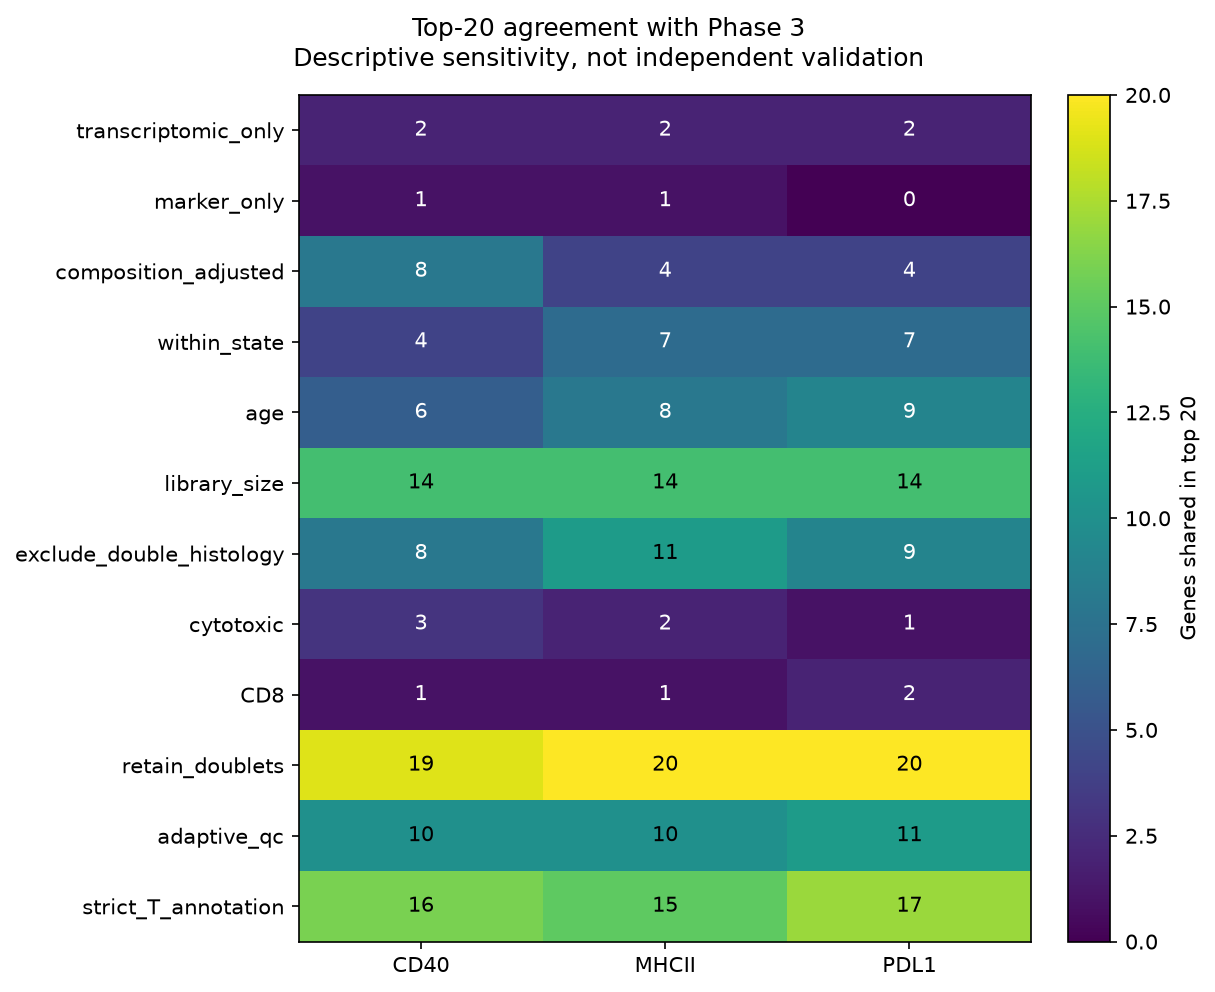

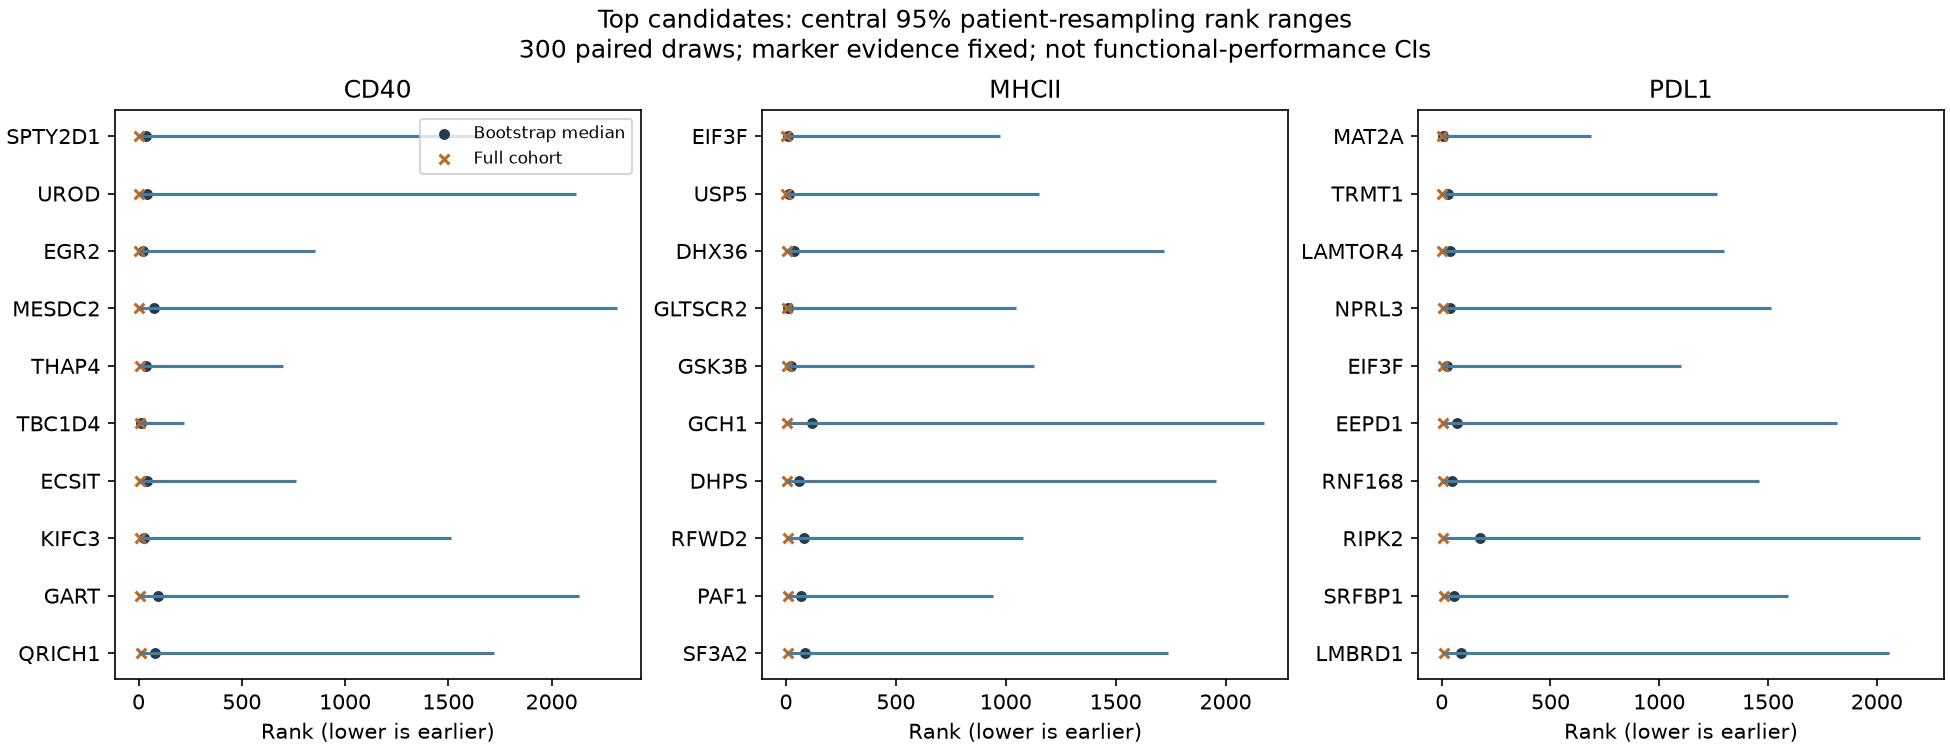

In [5]:
for name in ['phase4_ablations','phase4_rank_ranges']:
    display(Image(filename=str(ROOT/f'results/plots/{name}.png')))

In [6]:
RUN_PIPELINE=False
if RUN_PIPELINE:
    import subprocess,sys
    subprocess.run([sys.executable,str(ROOT/'phase4.py')],cwd=ROOT,check=True)

## Limits
Only 11 human patients and one quantitative mouse-marker study family. Bootstrap repeats whole patient pairs, holding marker evidence, annotation and gene selection fixed. Percentile ranges are exploratory, not calibrated CIs. Different T-cell endpoints are not independent replication. Missing test metrics remain missing. See reports/benchmark.md, reports/leakage_audit.md and reports/phase4_protocol.md.